In [19]:
import pandas as pd
import numpy as np

In [20]:
df = pd.read_csv("Data/Delhi_Master_Dataset.csv")

print(df.shape)
df.head()

(886073, 19)


,AirTemp,BuiltSurface,DistanceToWater,EVI,Elevation,LST,LandCover,Latitude,Longitude,Month,NDBI,NDVI,NDWI,Population,Slope,TreeCover,Year,WindSpeed,Humidity
0,31.713791,5513,5218.448045,0.307821,223,38.650293,50,28.632587,77.204405,5,-0.127111,0.406217,-0.386133,190.287857,3.489779,0.061827,2025,1.139496,46.328039
1,31.870379,4618,5018.615347,0.072727,219,42.017042,50,28.614531,77.114124,5,0.026058,0.090350,-0.114775,318.664734,1.854334,0.032390,2025,1.095888,45.640569
2,31.525858,0,8279.239095,0.177889,211,39.217684,80,28.783773,77.106847,5,0.047320,0.234292,-0.289397,0.000000,1.406886,0.046423,2025,1.188778,47.583937
3,31.711517,2576,2284.928883,0.279416,216,41.603462,50,28.660614,77.147272,5,-0.114370,0.431262,-0.425000,268.919067,2.307262,0.056690,2025,1.144877,46.826872
4,31.604455,0,2397.185850,0.422223,226,40.101242,40,28.814496,76.991773,5,-0.164912,0.594331,-0.582082,0.000000,4.263645,0.146633,2025,1.140920,46.906811


In [21]:
df.dtypes

AirTemp            float64
BuiltSurface         int64
DistanceToWater    float64
EVI                float64
Elevation            int64
LST                float64
LandCover            int64
Latitude           float64
Longitude          float64
Month                int64
NDBI               float64
NDVI               float64
NDWI               float64
Population         float64
Slope              float64
TreeCover          float64
Year                 int64
WindSpeed          float64
Humidity           float64
dtype: object

In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AirTemp,886073.0,22.610111,6.658184,11.768849,18.826032,21.663289,29.464029,34.487496
BuiltSurface,886073.0,1940.830452,2209.218397,0.000000,0.000000,877.000000,3808.000000,10000.000000
DistanceToWater,886073.0,4620.430260,3018.349066,0.000000,2222.836026,4224.038352,6442.251159,13955.160336
EVI,886073.0,0.213395,0.328914,-252.563025,0.089274,0.178753,0.301873,62.107969
Elevation,886073.0,221.906695,18.231314,182.000000,212.000000,216.000000,222.000000,312.000000
LST,886073.0,31.572814,9.418877,11.641099,24.550960,31.166538,38.971586,59.905250
LandCover,886073.0,38.199539,15.370020,10.000000,30.000000,40.000000,50.000000,90.000000
Latitude,886073.0,28.645277,0.107611,28.409445,28.560901,28.636629,28.729066,28.881600
Longitude,886073.0,77.107931,0.113751,76.833580,77.018184,77.117088,77.196050,77.336996
Month,886073.0,5.355938,3.722935,1.000000,3.000000,5.000000,11.000000,11.000000


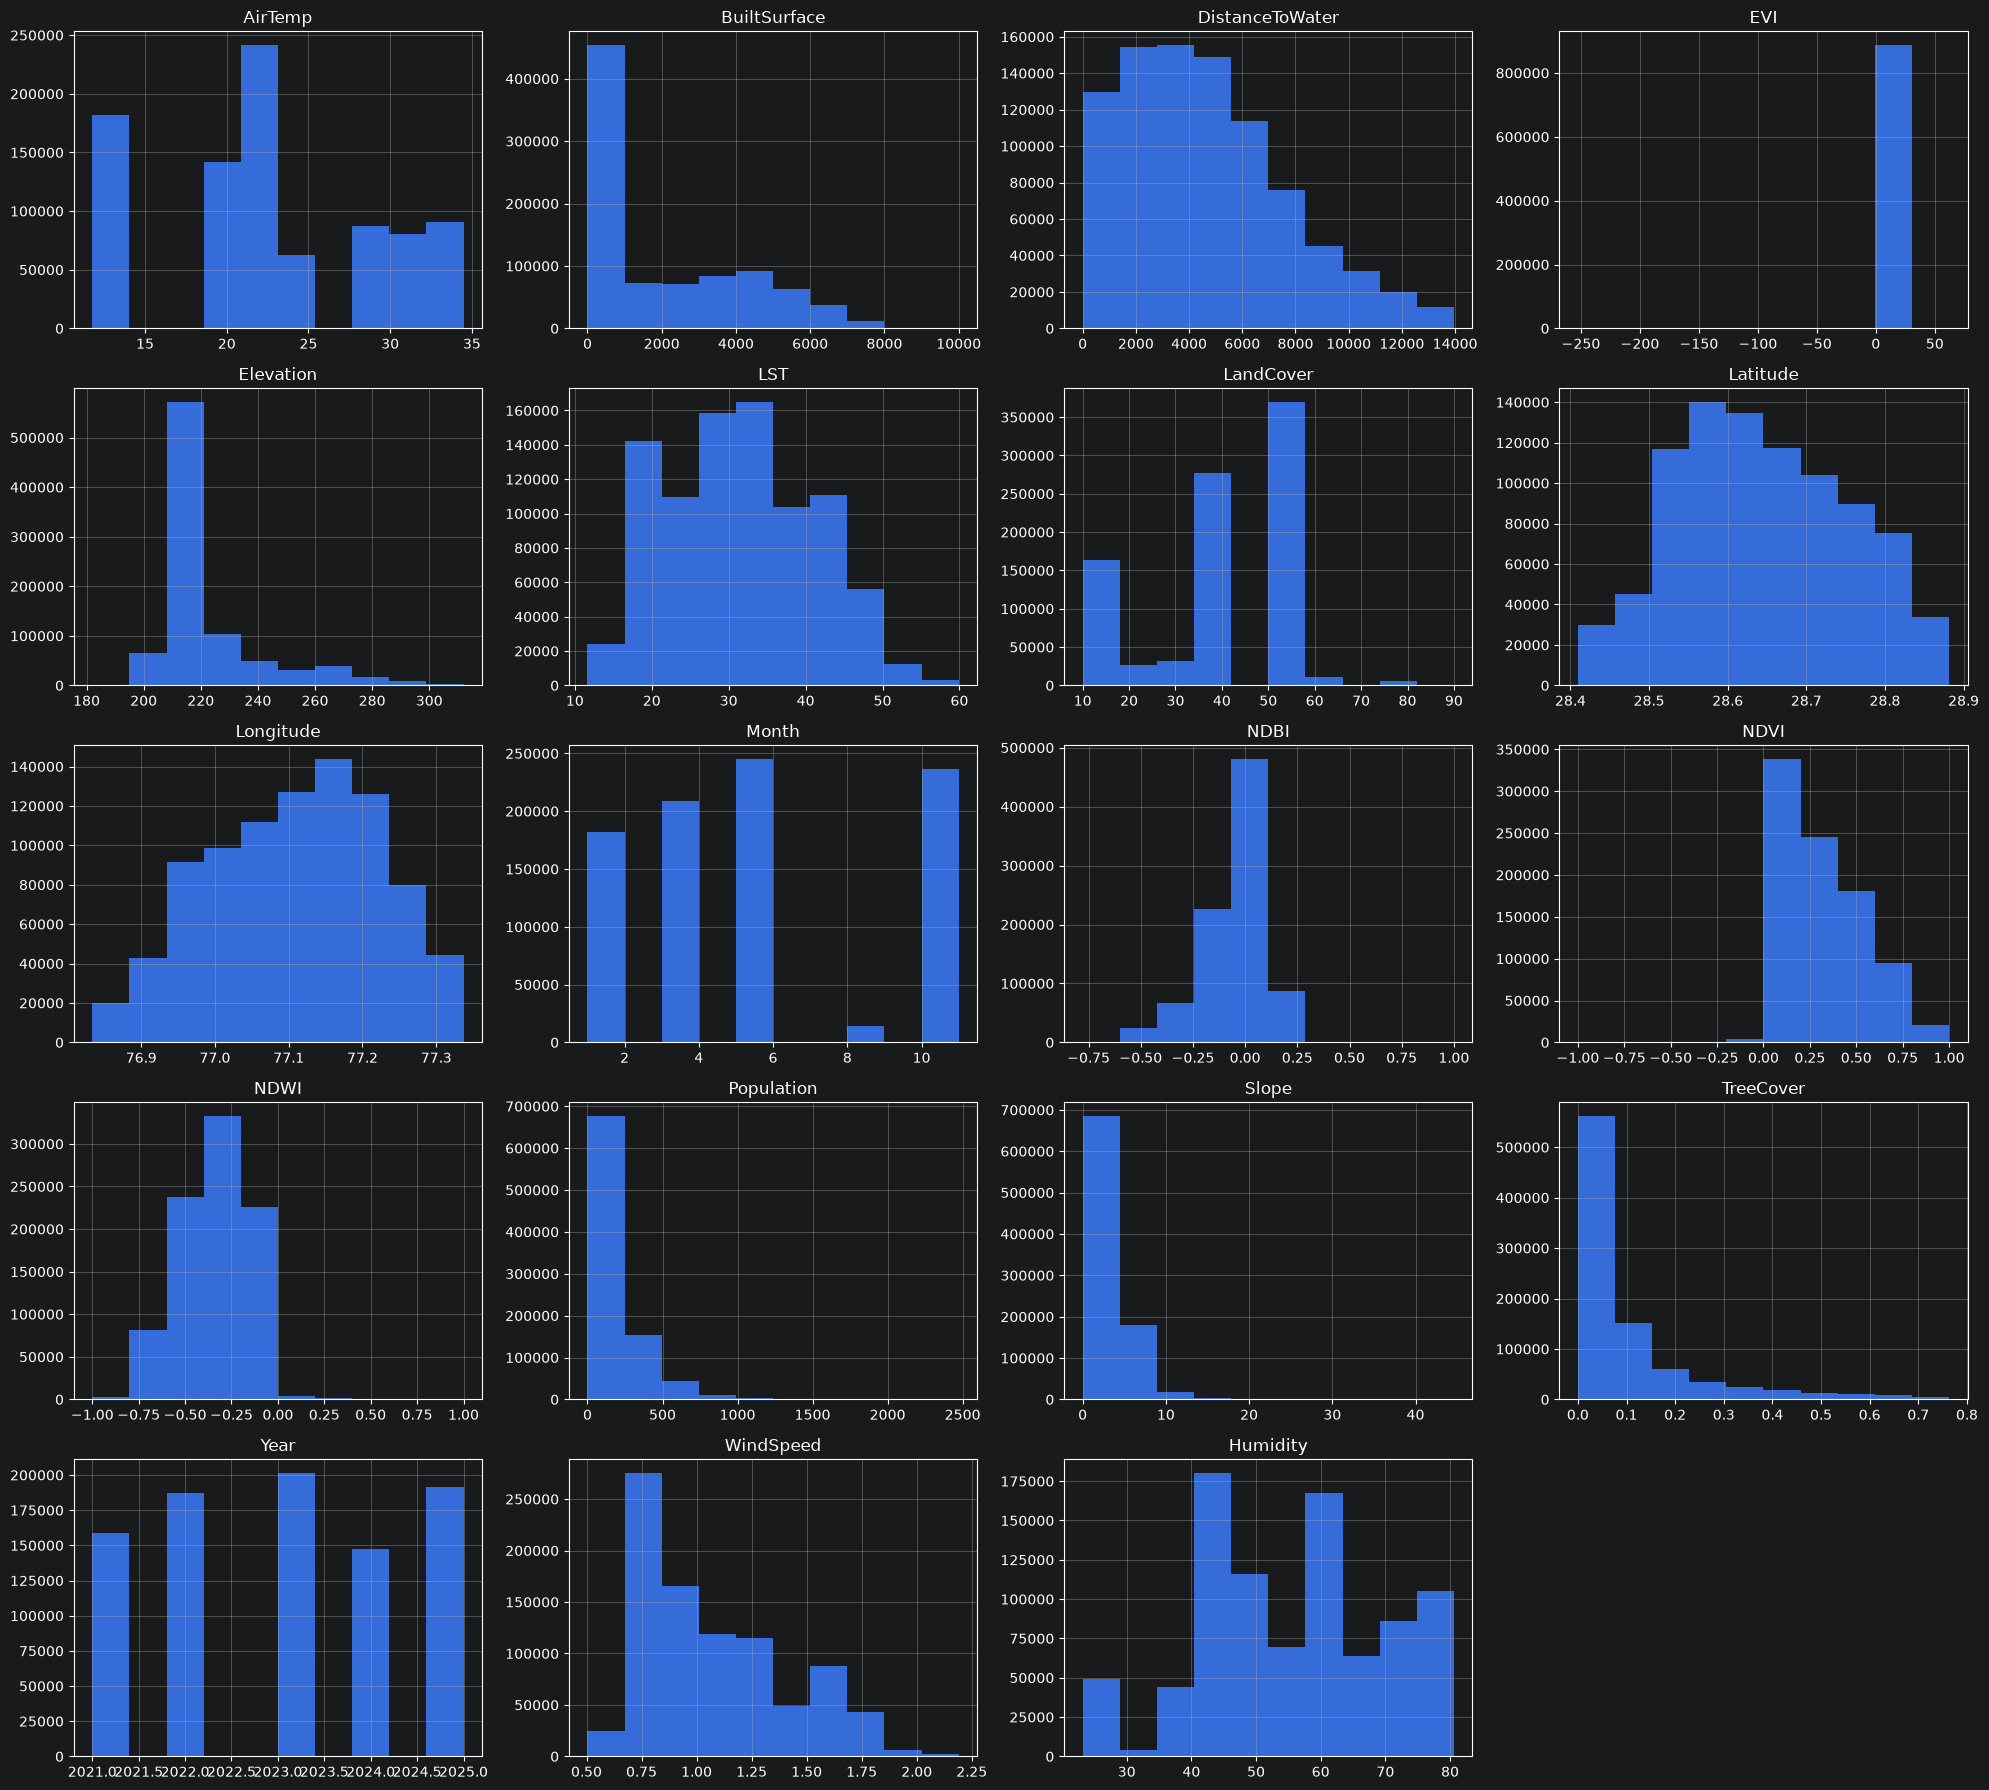

In [23]:
import matplotlib.pyplot as plt

df.hist(figsize=(20,18))
plt.tight_layout()
plt.show()

In [24]:
corr = df.corr(numeric_only=True)

print(corr["LST"].sort_values(ascending=False))

LST                1.000000
AirTemp            0.948139
NDBI               0.404774
Month              0.097091
NDWI               0.095276
Year               0.077235
LandCover          0.035422
DistanceToWater    0.025533
Elevation          0.001754
Slope              0.001126
BuiltSurface      -0.005182
Population        -0.016530
Latitude          -0.018977
Longitude         -0.076905
WindSpeed         -0.077741
EVI               -0.083764
NDVI              -0.196717
TreeCover         -0.265960
Humidity          -0.862609
Name: LST, dtype: float64


In [25]:
df["EVI"] = df["EVI"].clip(-1,1)

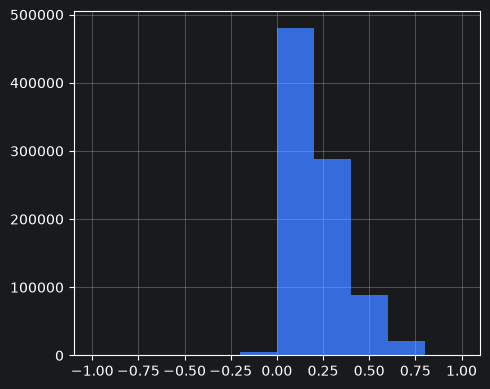

In [26]:
df["EVI"].hist(figsize=(5,4))
plt.tight_layout()
plt.show()

In [27]:
import numpy as np

df["Month_sin"] = np.sin(2*np.pi*df["Month"]/12)
df["Month_cos"] = np.cos(2*np.pi*df["Month"]/12)

In [28]:
df.head()

,AirTemp,BuiltSurface,DistanceToWater,EVI,Elevation,LST,LandCover,Latitude,Longitude,Month,...,NDVI,NDWI,Population,Slope,TreeCover,Year,WindSpeed,Humidity,Month_sin,Month_cos
0,31.713791,5513,5218.448045,0.307821,223,38.650293,50,28.632587,77.204405,5,...,0.406217,-0.386133,190.287857,3.489779,0.061827,2025,1.139496,46.328039,0.5,-0.866025
1,31.870379,4618,5018.615347,0.072727,219,42.017042,50,28.614531,77.114124,5,...,0.090350,-0.114775,318.664734,1.854334,0.032390,2025,1.095888,45.640569,0.5,-0.866025
2,31.525858,0,8279.239095,0.177889,211,39.217684,80,28.783773,77.106847,5,...,0.234292,-0.289397,0.000000,1.406886,0.046423,2025,1.188778,47.583937,0.5,-0.866025
3,31.711517,2576,2284.928883,0.279416,216,41.603462,50,28.660614,77.147272,5,...,0.431262,-0.425000,268.919067,2.307262,0.056690,2025,1.144877,46.826872,0.5,-0.866025
4,31.604455,0,2397.185850,0.422223,226,40.101242,40,28.814496,76.991773,5,...,0.594331,-0.582082,0.000000,4.263645,0.146633,2025,1.140920,46.906811,0.5,-0.866025


In [29]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AirTemp,886073.0,22.610111,6.658184,11.768849,18.826032,2.166329e+01,29.464029,34.487496
BuiltSurface,886073.0,1940.830452,2209.218397,0.000000,0.000000,8.770000e+02,3808.000000,10000.000000
DistanceToWater,886073.0,4620.430260,3018.349066,0.000000,2222.836026,4.224038e+03,6442.251159,13955.160336
EVI,886073.0,0.213344,0.154665,-1.000000,0.089274,1.787529e-01,0.301873,1.000000
Elevation,886073.0,221.906695,18.231314,182.000000,212.000000,2.160000e+02,222.000000,312.000000
LST,886073.0,31.572814,9.418877,11.641099,24.550960,3.116654e+01,38.971586,59.905250
LandCover,886073.0,38.199539,15.370020,10.000000,30.000000,4.000000e+01,50.000000,90.000000
Latitude,886073.0,28.645277,0.107611,28.409445,28.560901,2.863663e+01,28.729066,28.881600
Longitude,886073.0,77.107931,0.113751,76.833580,77.018184,7.711709e+01,77.196050,77.336996
Month,886073.0,5.355938,3.722935,1.000000,3.000000,5.000000e+00,11.000000,11.000000


In [30]:
train = df[df["Year"] <= 2023].copy()

val = df[df["Year"] == 2024].copy()

test = df[df["Year"] == 2025].copy()

In [33]:
train.Year.unique()

array([2021, 2022, 2023])

In [34]:
target = "LST"

X_train = train.drop(columns=[target])
y_train = train[target]

X_val = val.drop(columns=[target])
y_val = val[target]

X_test = test.drop(columns=[target])
y_test = test[target]

In [35]:
train.to_csv("train.csv", index=False)

val.to_csv("validation.csv", index=False)

test.to_csv("test.csv", index=False)